# 1.3 Binary classification with a Neural Network: HR Job Change

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jauniusc/cvmatch/blob/main/notebooks/1_3_hr_job_change_nn.ipynb)

Task 1.3. This notebook is based on the lecturer's notebook **"AdventureWorks DW using TensorFlow Neural Network"** (A. Laukaitis).
First I explain how the original works, then I redo it with business data from Kaggle.

## How the original notebook works

1. **Data.** It loads `vTargetMail.csv` from GitHub: 18,484 customers of the AdventureWorks company (age, income, children, cars, education, region...).
   The column `BikeBuyer` says if the customer bought a bike (1) or not (0). This is what the model has to predict.
2. **Cleaning.** It drops columns that are only IDs or personal info (name, email, phone, address...) because they don't help to predict anything.
   `BikeBuyer` is renamed to `target` so the code from the official TensorFlow tutorials can be reused without changes.
3. **Split.** The rows are shuffled and split 80/10/10 into training, validation and test sets.
   The model learns on *train*, *validation* shows overfitting during training, and *test* is used only once at the end.
4. **`df_to_dataset`.** Turns a pandas DataFrame into a `tf.data.Dataset` of `(features dict, label)` pairs, shuffled and split into batches of 256.
5. **Preprocessing layers inside the model.**
   - Text columns (`MaritalStatus`, `Gender`, `Region`...) go through `StringLookup` (word → number) and `CategoryEncoding` (number → one-hot vector).
     `HouseOwnerFlag` is already a number, so it uses `IntegerLookup`.
   - Number columns (`YearlyIncome`, `Age`...) go through `Normalization`: `(x - mean) / std`.
   - `adapt()` learns the vocabulary / mean / std from the **training data only**.
   Because preprocessing is part of the model, the saved model can take raw values (e.g. `'Pacific'`, `70000`) directly.
6. **Model.** All encoded features are joined with `concatenate` → `Dense(64, relu)` → `Dropout(0.2)` → `Dense(32, relu)` → `Dropout(0.3)` → `Dense(1)`.
   The last layer has no activation, so it outputs a *logit*. That is why the loss is `BinaryCrossentropy(from_logits=True)`
   and later `sigmoid` is used to turn the output into a probability. Dropout randomly switches off neurons during training to reduce overfitting.
7. **Training.** 30 epochs with the Adam optimizer. Test accuracy is about **0.75**.
8. **Inference.** The model is saved as a `.keras` file, loaded back, and used to predict for one new customer
   ("The likelihood of PURCHASING A BIKE ... is 97.7 percent").
9. **TensorBoard.** The last part trains again with a TensorBoard callback to look at the training curves.

## My data: HR Analytics, Job Change of Data Scientists (Kaggle)

Source: https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists (file `aug_train.csv`, saved in `data/hr_job_change/`).

A company runs data science courses and wants to know which participants are **looking for a new job** (`target = 1`) and which want to stay (`target = 0`).
HR can use this to plan hiring and courses. It fits my CVMatch project, which is also about candidates and jobs.

| Column | Meaning |
|---|---|
| `city_development_index` | how developed the candidate's city is (0–1) |
| `gender`, `education_level`, `major_discipline` | candidate info |
| `relevent_experience` | has relevant experience or not |
| `enrolled_university` | not enrolled / part time / full time |
| `experience` | years of experience (`<1`, `1`...`20`, `>20`) |
| `company_size`, `company_type` | current company |
| `last_new_job` | years since the previous job change |
| `training_hours` | hours of training completed |
| `target` | 1 = looking for a job change, 0 = not |

The task is the same type as in the original (one row = one person, predict yes/no), so the same code can be reused.

---
## Step 1. From the CSV file to 3 DataFrames: training, validation and test

In [1]:
import os
import pandas as pd

# The CSV is saved in this repo (data/hr_job_change/). Locally it is read from disk, in Colab from GitHub.
local_path = '../data/hr_job_change/aug_train.csv'
github_url = 'https://raw.githubusercontent.com/jauniusc/cvmatch/main/data/hr_job_change/aug_train.csv'
csv_path = local_path if os.path.exists(local_path) else github_url

df_all_col = pd.read_csv(csv_path)
print("The dataframe has {} rows and {} columns.".format(df_all_col.shape[0], df_all_col.shape[1]))

The dataframe has 19158 rows and 14 columns.


In [2]:
df_all_col.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


### Let's look at one row and at missing values

In [3]:
print(df_all_col.iloc[0])
print('---------------')
print(df_all_col.isna().sum())

enrollee_id                                  8949
city                                     city_103
city_development_index                       0.92
gender                                       Male
relevent_experience       Has relevent experience
enrolled_university                 no_enrollment
education_level                          Graduate
major_discipline                             STEM
experience                                    >20
company_size                                  NaN
company_type                                  NaN
last_new_job                                    1
training_hours                                 36
target                                        1.0
Name: 0, dtype: object
---------------
enrollee_id                  0
city                         0
city_development_index       0
gender                    4508
relevent_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience   

In [4]:
# How many candidates are looking for a new job?
print(df_all_col['target'].value_counts(normalize=True))

target
0.0    0.750652
1.0    0.249348
Name: proportion, dtype: float64


About 25% of candidates have `target = 1`. So a "model" that always answers 0 would already get **~75% accuracy**.
I will remember this when looking at the results.

### Remove attributes we don't need
- `enrollee_id` is just an ID.
- `city` has 123 different city codes. `city_development_index` already describes the city with one number, so I drop `city`.
- Text columns have missing values (NaN). `StringLookup` can't work with NaN, so I replace them with `'Unknown'`.
- `target` is stored as `0.0 / 1.0`, I convert it to int.
- `experience` and `last_new_job` contain values like `>20` and `never`, so I keep them as text categories (like `CommuteDistance` in the original).

In [5]:
df = df_all_col.copy()

df = df.drop(columns=['enrollee_id', 'city'])
df['target'] = df['target'].astype('int64')

categorical_cols = ['gender', 'relevent_experience', 'enrolled_university', 'education_level',
                    'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job']
numeric_cols = ['city_development_index', 'training_hours']

df[categorical_cols] = df[categorical_cols].fillna('Unknown').astype(str)
df[numeric_cols] = df[numeric_cols].astype('float32')

print(df.iloc[0])
print('---------------')
print(df.dtypes)

city_development_index                       0.92
gender                                       Male
relevent_experience       Has relevent experience
enrolled_university                 no_enrollment
education_level                          Graduate
major_discipline                             STEM
experience                                    >20
company_size                              Unknown
company_type                              Unknown
last_new_job                                    1
training_hours                               36.0
target                                          1
Name: 0, dtype: object
---------------
city_development_index    float32
gender                        str
relevent_experience           str
enrolled_university           str
education_level               str
major_discipline              str
experience                    str
company_size                  str
company_type                  str
last_new_job                  str
training_hours       

### Split into training, validation and test sets (80:10:10)
The original uses `np.split(df.sample(frac=1), ...)`. Newer pandas shows a FutureWarning for that, so I do the same thing with `iloc`.

In [6]:
import numpy as np

df = df.sample(frac=1, random_state=42)   # shuffle all rows
n = len(df)
train = df.iloc[:int(0.8 * n)]
validation = df.iloc[int(0.8 * n):int(0.9 * n)]
test = df.iloc[int(0.9 * n):]

print(len(train), 'training examples')
print(len(validation), 'validation examples')
print(len(test), 'test examples')

15326 training examples
1916 validation examples
1916 test examples


---
## Step 2. From DataFrame to a TensorFlow dataset
Same function as in the original.

In [7]:
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

def df_to_dataset(dataframe, shuffle=True, batch_size=32):
  df = dataframe.copy()
  labels = df.pop('target')
  df = {key: value.to_numpy()[:, tf.newaxis] for key, value in df.items()}
  ds = tf.data.Dataset.from_tensor_slices((dict(df), labels))
  if shuffle:
    ds = ds.shuffle(buffer_size=len(dataframe))
  ds = ds.batch(batch_size)
  ds = ds.prefetch(batch_size)
  return ds


batch_size = 256
train_ds = df_to_dataset(train, batch_size=batch_size)
validation_ds = df_to_dataset(validation, shuffle=False, batch_size=batch_size)
test_ds = df_to_dataset(test, shuffle=False, batch_size=batch_size)

---
## Step 3. Model

In [8]:
all_inputs = {}
encoded_features = []

### Categorical columns (text → one-hot)

In [9]:
def get_category_encoding_layer(name, dataset, dtype, max_tokens=None):
  if dtype == 'string':
    index = tf.keras.layers.StringLookup(max_tokens=max_tokens)
  else:
    index = tf.keras.layers.IntegerLookup(max_tokens=max_tokens)
  feature_ds = dataset.map(lambda x, y: x[name])   # only this one column
  index.adapt(feature_ds)                          # learn all possible values
  encoder = tf.keras.layers.CategoryEncoding(num_tokens=index.vocabulary_size())
  return lambda feature: encoder(index(feature))


for header in categorical_cols:
  categorical_col = tf.keras.Input(shape=(1,), name=header, dtype='string')
  encoding_layer = get_category_encoding_layer(name=header, dataset=train_ds, dtype='string')
  all_inputs[header] = categorical_col
  encoded_features.append(encoding_layer(categorical_col))

### Numerical columns (normalization)

In [10]:
def get_normalization_layer(name, dataset):
  normalizer = tf.keras.layers.Normalization(axis=None)
  feature_ds = dataset.map(lambda x, y: x[name])
  normalizer.adapt(feature_ds)                     # learn mean and variance
  return normalizer


for header in numeric_cols:
  numeric_col = tf.keras.Input(shape=(1,), name=header)
  normalization_layer = get_normalization_layer(header, train_ds)
  all_inputs[header] = numeric_col
  encoded_features.append(normalization_layer(numeric_col))

In [11]:
all_features = tf.keras.layers.concatenate(encoded_features)
print('Number of features after encoding:', all_features.shape[-1])

Number of features after encoding: 80


### Add layers of neurons and create the final model
Same layers as the original. I only added the **AUC** metric: because only 25% of rows are 1, accuracy alone can look good even for a bad model.
AUC shows how well the model ranks candidates (0.5 = random guessing, 1.0 = perfect).

In [12]:
x = tf.keras.layers.Dense(64, activation="relu")(all_features)
x = tf.keras.layers.Dropout(0.2)(x)
x = tf.keras.layers.Dense(32, activation="relu")(x)
x = tf.keras.layers.Dropout(0.3)(x)
output = tf.keras.layers.Dense(1)(x)

model = tf.keras.Model(all_inputs, output)

model.compile(optimizer='adam',
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=['accuracy', tf.keras.metrics.AUC(from_logits=True, name='auc')])

---
## Step 4. Train and evaluate the model
### Train 🏃‍♂️

In [13]:
history = model.fit(train_ds, validation_data=validation_ds, epochs=30, verbose=2)

Epoch 1/30


60/60 - 1s - 18ms/step - accuracy: 0.7500 - auc: 0.6419 - loss: 0.5450 - val_accuracy: 0.7526 - val_auc: 0.7714 - val_loss: 0.4775


Epoch 2/30


60/60 - 0s - 1ms/step - accuracy: 0.7519 - auc: 0.7547 - loss: 0.4854 - val_accuracy: 0.7521 - val_auc: 0.7917 - val_loss: 0.4555


Epoch 3/30


...

60/60 - 0s - 1ms/step - accuracy: 0.7719 - auc: 0.8222 - loss: 0.4283 - val_accuracy: 0.7657 - val_auc: 0.8017 - val_loss: 0.4399


Epoch 29/30


60/60 - 0s - 1ms/step - accuracy: 0.7703 - auc: 0.8244 - loss: 0.4264 - val_accuracy: 0.7662 - val_auc: 0.8008 - val_loss: 0.4437


Epoch 30/30


60/60 - 0s - 1ms/step - accuracy: 0.7723 - auc: 0.8266 - loss: 0.4244 - val_accuracy: 0.7683 - val_auc: 0.8007 - val_loss: 0.4418


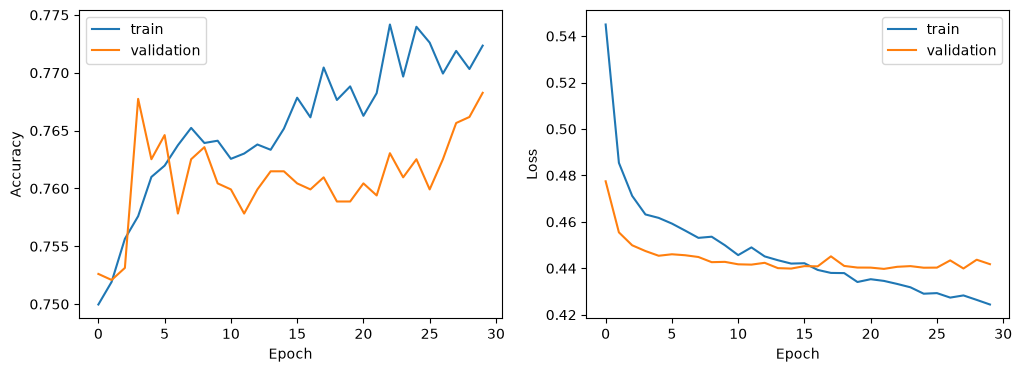

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()
plt.show()

### Evaluate ⚖️

In [15]:
loss, accuracy, auc = model.evaluate(test_ds, verbose=0)
baseline = 1 - test['target'].mean()   # accuracy if we always answer 0

print(f"Test accuracy: {accuracy:.4f}")
print(f"Test AUC:      {auc:.4f}")
print(f"Baseline (always 0) accuracy: {baseline:.4f}")

Test accuracy: 0.7651
Test AUC:      0.7944
Baseline (always 0) accuracy: 0.7516


---
## Step 5. Perform inference 🛠
### Save 💾 and load ⚙️

In [16]:
model.save('hr_job_change_NNModel_L64L32L1.keras')
reloaded_model = tf.keras.models.load_model('hr_job_change_NNModel_L64L32L1.keras')

### New data 🗃️
Two made-up candidates: a junior from a less developed city who is studying full time,
and an experienced data scientist in a big company in a well developed city.

In [17]:
candidates = {
    'Junior, studying full time': {
        'city_development_index': 0.62, 'gender': 'Male', 'relevent_experience': 'No relevent experience',
        'enrolled_university': 'Full time course', 'education_level': 'Graduate', 'major_discipline': 'STEM',
        'experience': '2', 'company_size': 'Unknown', 'company_type': 'Unknown', 'last_new_job': 'never',
        'training_hours': 40,
    },
    'Senior in a big company': {
        'city_development_index': 0.92, 'gender': 'Female', 'relevent_experience': 'Has relevent experience',
        'enrolled_university': 'no_enrollment', 'education_level': 'Masters', 'major_discipline': 'STEM',
        'experience': '>20', 'company_size': '10000+', 'company_type': 'Pvt Ltd', 'last_new_job': '4',
        'training_hours': 20,
    },
}

### Predict 🔮

In [18]:
for name, sample in candidates.items():
  input_dict = {key: tf.convert_to_tensor([value]) for key, value in sample.items()}
  prediction = reloaded_model.predict(input_dict, verbose=0)
  prob = tf.nn.sigmoid(prediction[0][0])
  print(f"{name}: the likelihood that this candidate is LOOKING FOR A NEW JOB is {100 * prob:.1f} percent.")

Junior, studying full time: the likelihood that this candidate is LOOKING FOR A NEW JOB is 57.6 percent.
Senior in a big company: the likelihood that this candidate is LOOKING FOR A NEW JOB is 9.1 percent.


---
## Results and conclusions

| | Accuracy | AUC |
|---|---|---|
| Always answer 0 (baseline) | 0.752 | 0.5 |
| **My neural network** | **0.765** | **0.794** |

- Only 25% of candidates are looking for a new job, so answering "no" every time already gives 0.752 accuracy.
  AUC 0.79 shows that the model really learned something (0.5 = random guessing).
- Validation accuracy and loss stop improving after ~10 epochs, so 30 epochs is more than needed.
- The predictions make sense: the junior who is studying gets ~58%, the senior in a big company ~9%.
- The same code from the original worked on different data after changing only the column lists.